<a href="https://colab.research.google.com/github/JayTea704/mis433/blob/main/JB_assignment_IMDB_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment - Analyzing the IMDB Top 1000 Movies

In this assignment, you will be working with this dataset of IMDB top 1000 movies.

Source: https://www.kaggle.com/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows

In [1]:
import pandas as pd
import numpy as np

In [2]:
# Read the data file "imdb_top_1000.csv" to a dataframe named "imdb"
imdb = pd.read_csv('https://raw.githubusercontent.com/jiexunli-wwu/mis433/refs/heads/main/data/imdb_top_1000.csv', header=0)
imdb.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


In [3]:
# Describe the dataframe using the info() method.
imdb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   object 
 1   Series_Title   1000 non-null   object 
 2   Released_Year  1000 non-null   object 
 3   Certificate    899 non-null    object 
 4   Runtime        1000 non-null   object 
 5   Genre          1000 non-null   object 
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   object 
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   object 
 10  Star1          1000 non-null   object 
 11  Star2          1000 non-null   object 
 12  Star3          1000 non-null   object 
 13  Star4          1000 non-null   object 
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    object 
dtypes: float64(2), int64(1), object(13)
memory usage: 125.1+ KB


In [ ]:
# List all the column names:
imdb.columns

Index(['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate',
       'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director',
       'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross'],
      dtype='object')

## Part 1: Data Manipulation

Redo the following to clean the data.

In [4]:
# Count the number of movies in each "Released_Year".
# Hint: value_counts()
imdb.value_counts("Released_Year")

,count
Released_Year,
2014,32
2004,31
2009,29
2016,28
2013,28
...,...
1936,1
1930,1
1921,1


In [5]:
# In this dataset, there is a movie with an error in "Released_Year".
# Hint: Released_Year should be a 4-digit integer but this movie's year is not.
# Find this movie.
imdb[imdb.Released_Year.str.len() != 4]

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
966,https://m.media-amazon.com/images/M/MV5BNjEzYj...,Apollo 13,PG,U,140 min,"Adventure, Drama, History",7.6,NASA must devise a strategy to return Apollo 1...,77.0,Ron Howard,Tom Hanks,Bill Paxton,Kevin Bacon,Gary Sinise,269197,"173,837,933"


In [6]:
# Correct the values for the corresponding columns ("Released_Year" and "Certificate").
# You may want to look up this movie on www.imdb.com.
# Hint: You can set value for a particular row by: df.loc[row_index, column_name] = new_value
imdb.loc[966, "Released_Year"] = "1995"
imdb.loc[966, "Certificate"] = "PG"

imdb.loc[966]

,966
Poster_Link,https://m.media-amazon.com/images/M/MV5BNjEzYj...
Series_Title,Apollo 13
Released_Year,1995
Certificate,PG
Runtime,140 min
Genre,"Adventure, Drama, History"
IMDB_Rating,7.6
Overview,NASA must devise a strategy to return Apollo 1...
Meta_score,77.0
Director,Ron Howard


In [7]:
# Change the data type of "Released_Year" to int
imdb.Released_Year = imdb.Released_Year.astype(int)
imdb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   object 
 1   Series_Title   1000 non-null   object 
 2   Released_Year  1000 non-null   int64  
 3   Certificate    899 non-null    object 
 4   Runtime        1000 non-null   object 
 5   Genre          1000 non-null   object 
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   object 
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   object 
 10  Star1          1000 non-null   object 
 11  Star2          1000 non-null   object 
 12  Star3          1000 non-null   object 
 13  Star4          1000 non-null   object 
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    object 
dtypes: float64(2), int64(2), object(12)
memory usage: 125.1+ KB


In [8]:
# Select all movies released after (>=) 2010 and with IMDB_Rating>=8.5
# Show their Series_Title, Released_Year, Certificate, and Gross.
# Sort them in descending order of "Gross"
(
    imdb[(imdb.Released_Year >= 2010) & (imdb.IMDB_Rating >= 8.5)]
    .loc[:, ["Series_Title", "Released_Year", "Certificate", "Gross"]]
    .sort_values("Gross", ascending=False)
)

,Series_Title,Released_Year,Certificate,Gross
19,Gisaengchung,2019,A,"53,367,844"
33,Joker,2019,A,"335,451,311"
8,Inception,2010,UA,"292,576,195"
21,Interstellar,2014,UA,"188,020,017"
35,The Intouchables,2011,UA,"13,182,281"
34,Whiplash,2014,A,"13,092,000"
18,Hamilton,2020,PG-13,NaN
20,Soorarai Pottru,2020,U,NaN


In [9]:
# Does the sorting result look right to you? What's the problem?
#That is not the correct order but my code is correct
#The Gross columb is stored as a string with commas
imdb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   object 
 1   Series_Title   1000 non-null   object 
 2   Released_Year  1000 non-null   int64  
 3   Certificate    899 non-null    object 
 4   Runtime        1000 non-null   object 
 5   Genre          1000 non-null   object 
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   object 
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   object 
 10  Star1          1000 non-null   object 
 11  Star2          1000 non-null   object 
 12  Star3          1000 non-null   object 
 13  Star4          1000 non-null   object 
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    object 
dtypes: float64(2), int64(2), object(12)
memory usage: 125.1+ KB


In [10]:
# Resolve this problem of "Gross" and convert its data type to float
# Hint: You may find this webpage useful:
# https://stackoverflow.com/questions/28986489/how-to-replace-text-in-a-column-of-a-pandas-dataframe
imdb.Gross = imdb.Gross.str.replace(",", "").astype(float)
imdb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   object 
 1   Series_Title   1000 non-null   object 
 2   Released_Year  1000 non-null   int64  
 3   Certificate    899 non-null    object 
 4   Runtime        1000 non-null   object 
 5   Genre          1000 non-null   object 
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   object 
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   object 
 10  Star1          1000 non-null   object 
 11  Star2          1000 non-null   object 
 12  Star3          1000 non-null   object 
 13  Star4          1000 non-null   object 
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    float64
dtypes: float64(3), int64(2), object(11)
memory usage: 125.1+ KB


In [11]:
# Next, redo the sorting on Gross

# Select all movies released after (>=) 2010 and with IMDB_Rating>=8.5
# Show their Series_Title, Released_Year, Certificate, and Gross.
# Sort them in descending order of "Gross"
(
    imdb[(imdb.Released_Year >= 2010) & (imdb.IMDB_Rating >= 8.5)]
    .loc[:, ["Series_Title", "Released_Year", "Certificate", "Gross"]]
    .sort_values("Gross", ascending=False)
)

,Series_Title,Released_Year,Certificate,Gross
33,Joker,2019,A,335451311.0
8,Inception,2010,UA,292576195.0
21,Interstellar,2014,UA,188020017.0
19,Gisaengchung,2019,A,53367844.0
35,The Intouchables,2011,UA,13182281.0
34,Whiplash,2014,A,13092000.0
18,Hamilton,2020,PG-13,NaN
20,Soorarai Pottru,2020,U,NaN


In [12]:
# Add a new column "Runtime_min" by removing the substring " min" in "Runtime"
# Set its data type as int
# Hint: https://stackoverflow.com/questions/36505847/substring-of-an-entire-column-in-pandas-dataframe
imdb["Runtime_min"] = imdb.Runtime.str.replace(" min", "").astype(int)
imdb[["Runtime", "Runtime_min"]].head()

,Runtime,Runtime_min
0,142 min,142
1,175 min,175
2,152 min,152
3,202 min,202
4,96 min,96


In [13]:
# Add a new column "Age_Years" by the expression: Current year - Released_Year
imdb["Age_Years"] = 2026 - imdb["Released_Year"]
imdb[["Age_Years", "Released_Year"]]

,Age_Years,Released_Year
0,32,1994
1,54,1972
2,18,2008
3,52,1974
4,69,1957
...,...,...
995,65,1961
996,70,1956
997,73,1953
998,82,1944


In [14]:
# Add a new column "Decade" with values as 1980, 1990, 2000, 2010, 2020, etc.
imdb["Decade"] = imdb["Released_Year"] // 10 * 10
imdb[["Released_Year", "Decade"]].head()

,Released_Year,Decade
0,1994,1990
1,1972,1970
2,2008,2000
3,1974,1970
4,1957,1950


## Part 2: Data Summarization

Done!

## Part 3: Data Visualization

Finish Part 1 (data manipulation) before you work through this section.

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

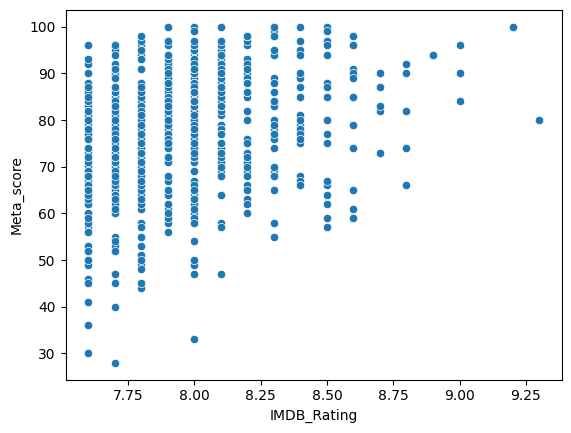

In [ ]:
# Create a scatterplot of the two scores, "IMDB_Rating" and "Meta_score".
# In a sentence or two, describe what this pair of scores suggests about the movies.
sns.scatterplot(data=imdb, x = "IMDB_Rating", y = 'Meta_score')
plt.show()

This suggests that movies with a higher IMDB rating will also likely have a higher metacritic score. This makes sense as both scoring systems are supposed to reflect critc opinion.

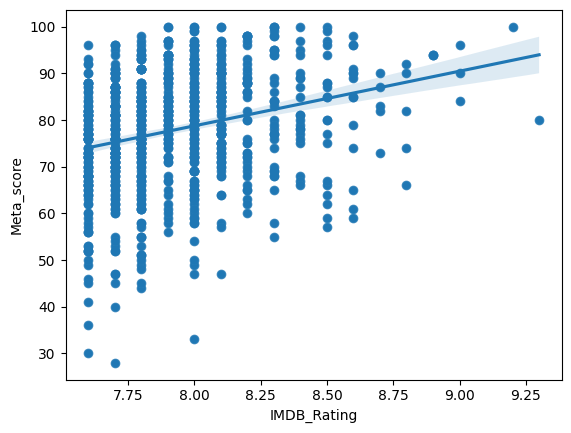

In [ ]:
# Fit a trendline to show the relationship between the two scores.
# Hint: sns.regplot()
# Try a few values of the `order` argument (polynomial degree) for the trendline.
sns.scatterplot(data=imdb, x = "IMDB_Rating", y = 'Meta_score')
sns.regplot(data=imdb, x = "IMDB_Rating", y = 'Meta_score', order = 1)
plt.show()

In [ ]:
# Do any data points in the scatterplot surprise you?
# Try to identify a few such movies.

#Some of the movies that have higher IMDB ratings but very low meta scores are surprising

imdb[(imdb.IMDB_Rating >= 7) & (imdb.Meta_score <= 40)]

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross,Runtime_min,Age_Years,Decade
356,https://m.media-amazon.com/images/M/MV5BYmI1OD...,Tropa de Elite,2007,R,115 min,"Action, Crime, Drama",8.0,"In 1997 Rio de Janeiro, Captain Nascimento has...",33.0,José Padilha,Wagner Moura,André Ramiro,Caio Junqueira,Milhem Cortaz,98097,8060.0,115,19,2000
735,https://m.media-amazon.com/images/M/MV5BMTgwNT...,Kai po che!,2013,U,130 min,"Drama, Sport",7.7,Three friends growing up in India at the turn ...,40.0,Abhishek Kapoor,Amit Sadh,Sushant Singh Rajput,Rajkummar Rao,Amrita Puri,32628,1122527.0,130,13,2010
788,https://m.media-amazon.com/images/M/MV5BYzEyNz...,I Am Sam,2001,PG-13,132 min,Drama,7.7,A mentally handicapped man fights for custody ...,28.0,Jessie Nelson,Sean Penn,Michelle Pfeiffer,Dakota Fanning,Dianne Wiest,142863,40311852.0,132,25,2000
917,https://m.media-amazon.com/images/M/MV5BMTU0Nz...,Seven Pounds,2008,UA,123 min,Drama,7.6,A man with a fateful secret embarks on an extr...,36.0,Gabriele Muccino,Will Smith,Rosario Dawson,Woody Harrelson,Michael Ealy,286770,69951824.0,123,18,2000
942,https://m.media-amazon.com/images/M/MV5BODNiZm...,The Butterfly Effect,2004,U,113 min,"Drama, Sci-Fi, Thriller",7.6,Evan Treborn suffers blackouts during signific...,30.0,Eric Bress,J. Mackye Gruber,Ashton Kutcher,Amy Smart,Melora Walters,451479,57938693.0,113,22,2000


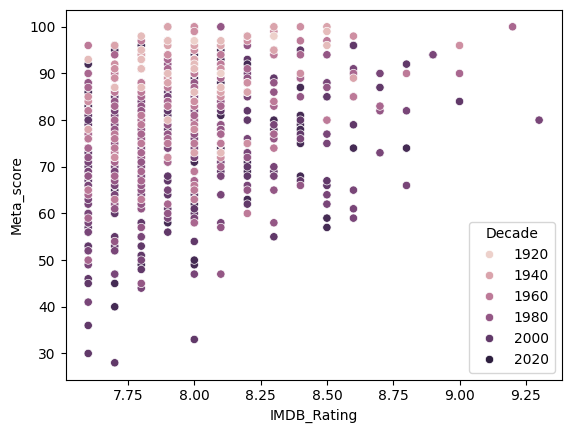

In [ ]:
# In the scatterplot, use color to distinguish movies from different decades.
sns.scatterplot(data=imdb, x = "IMDB_Rating", y = 'Meta_score', hue = "Decade")
plt.show()

<Axes: xlabel='Decade', ylabel='count'>

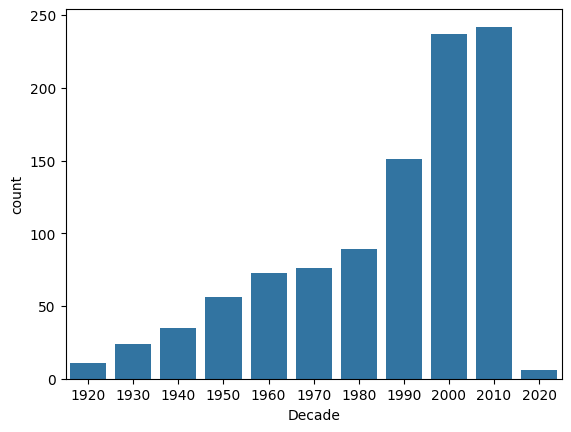

In [ ]:
# Create a chart that shows how many movies fall into each decade.
sns.countplot(data=imdb, x="Decade")

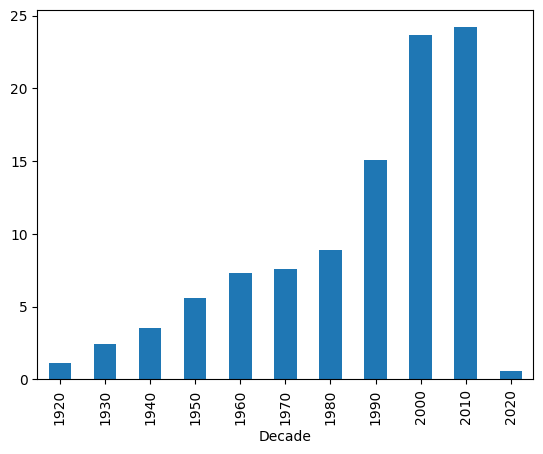

In [ ]:
# Create a chart that shows the percentage of movies in each decade.
(
    imdb.Decade.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .plot(kind="bar")
)
plt.show()

<Axes: ylabel='Director'>

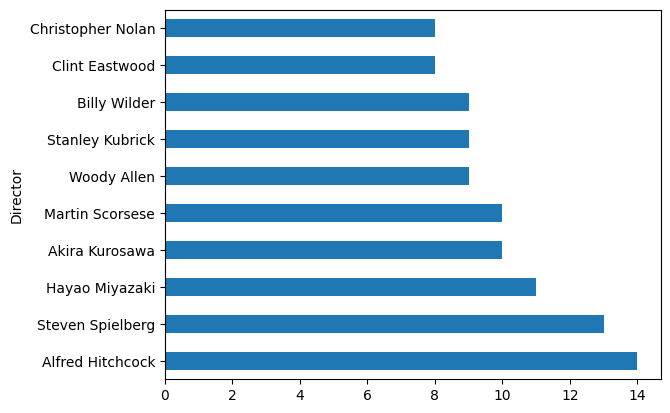

In [ ]:
# Count movies by director.
# Show the top 10 directors by movie count in a bar chart.
imdb.Director.value_counts().head(10).plot(kind="barh")

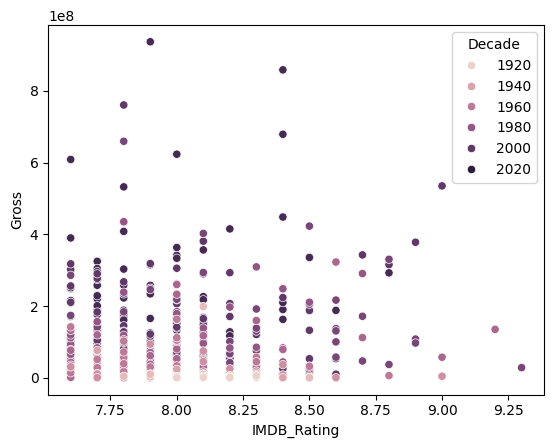

In [ ]:
# Create a scatterplot of "IMDB_Rating" and "Gross".
# Use color to distinguish movies from different decades.
# Briefly interpret what the chart shows.
sns.scatterplot(data=imdb, x = "IMDB_Rating", y = 'Gross', hue = "Decade")
plt.show()

This chart shows that an exceptionaly high imdb rating does not always relate to a high grossing film

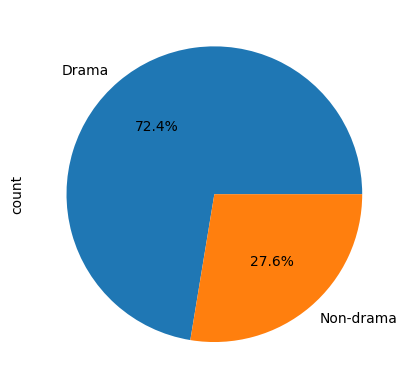

In [29]:
# Create a column named "Drama" that indicates whether a movie's Genre includes "Drama".
# Create a pie chart showing the share of drama vs. non-drama movies.
imdb["Drama"] = imdb.Genre.str.contains("Drama")
imdb[["Genre", "Drama"]].head()

(
    imdb.Drama.map({True: "Drama", False: "Non-drama"})
    .value_counts()
    .plot(kind="pie", autopct="%1.1f%%")
)
plt.show()

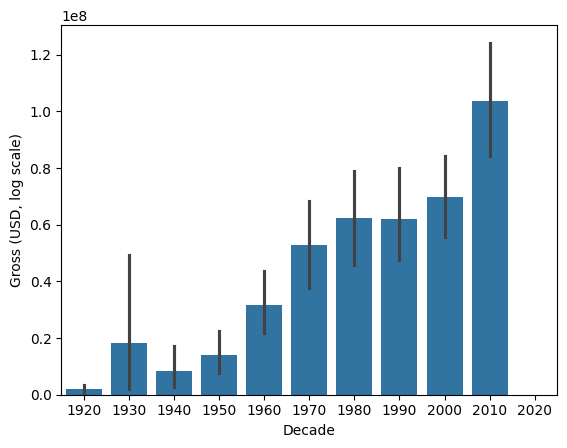

In [24]:
# Create a plot comparing Gross across decades.
sns.barplot(data=imdb, x="Decade", y="Gross")
plt.ylabel("Gross (USD, log scale)")
plt.show()

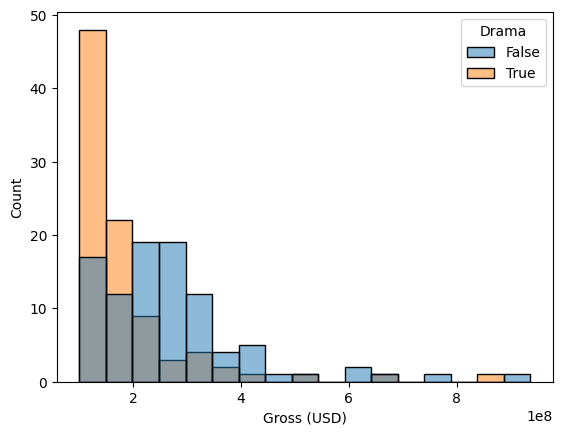

In [25]:
# For movies with Gross over $100 million:
# Create a histogram of Gross for drama vs. non-drama movies.
big = imdb[imdb.Gross > 100_000_000]
sns.histplot(data=big, x="Gross", hue="Drama")
plt.xlabel("Gross (USD)")
plt.show()

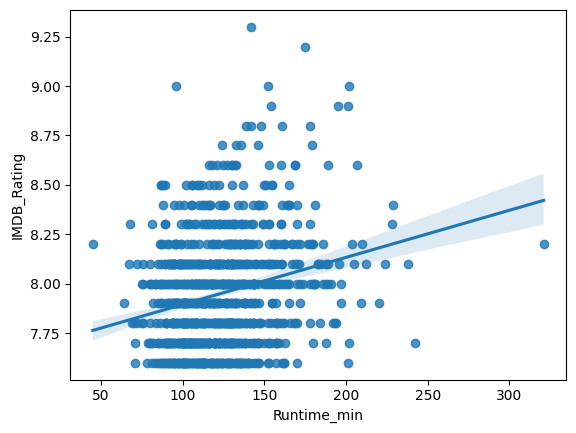

In [26]:
# Come up with two more questions about this dataset. Create one chart or figure for each.
# Question 1: Do longer movies receive higher IMDB ratings?
sns.regplot(data=imdb, x="Runtime_min", y="IMDB_Rating")
plt.show()

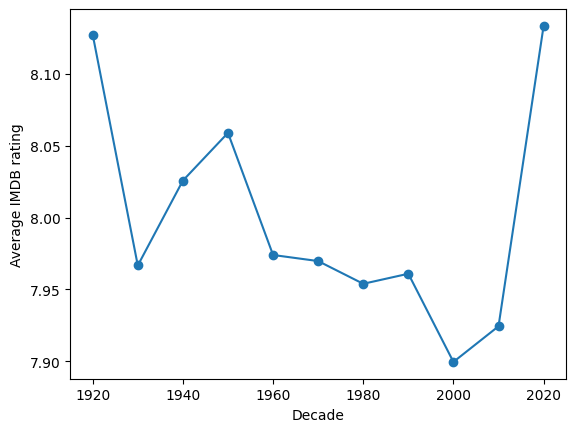

In [27]:
# Question 2: How has the average IMDB rating changed by decade?
imdb.groupby("Decade").IMDB_Rating.mean().plot(kind="line", marker="o")
plt.ylabel("Average IMDB rating")
plt.show()